Flow mixer example (Victor Z and Ugochukwu Ikegwu, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $\omega$ | `omega` | observation (time) index |
| $S$ | `S` | number of observations |
| $f_1(\omega)$, $f_2(\omega)$, $f_3(\omega)$ | `f1`, `f2`, `f3` | measured flows [gpm] |
| $\epsilon(\omega)$ | `epsilon` | conservation mismatch $f_3-f_1-f_2$ |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Simulate $S=100$ sensor readings of each flow (sensor noise of about 1%) and compute the
mismatch $\epsilon(\omega)=f_3(\omega)-f_1(\omega)-f_2(\omega)$.

In [2]:
np.random.seed(0)  # reproducibility
S = 100
omega = np.arange(S)
f1 = np.random.normal(100, 100*0.01/2.5, S)
f2 = np.random.normal(50, 50*0.01/2.5, S)
f3 = np.random.normal(150, 150*0.01/2.5, S)

epsilon = f3 - f1 - f2   # conservation mismatch

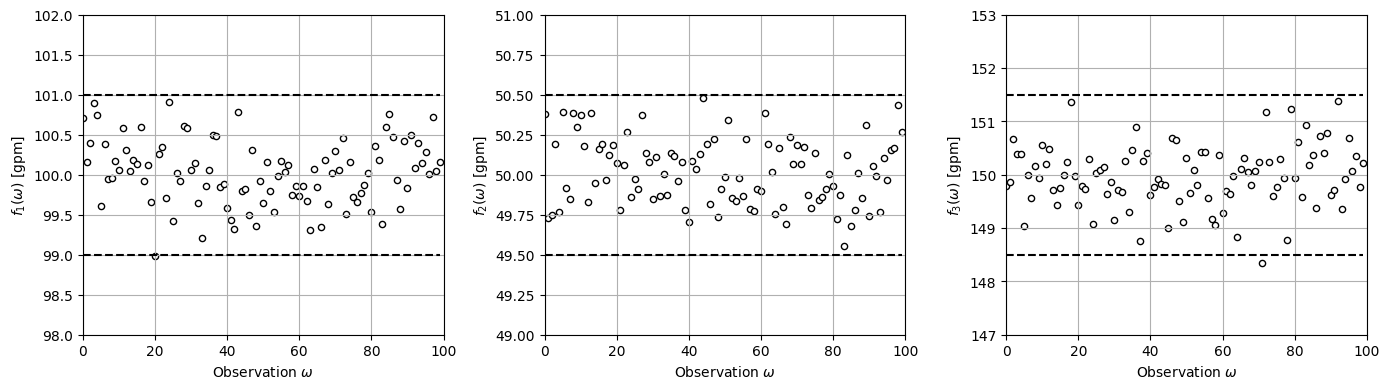

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, f_k, nominal, label in zip(axs, (f1, f2, f3), (100, 50, 150), ('f_1', 'f_2', 'f_3')):
    ax.scatter(omega, f_k, marker='o', s=20, color='white', edgecolor='black')
    ax.plot(omega, nominal * 1.01 * np.ones(S), 'k--')
    ax.plot(omega, nominal * 0.99 * np.ones(S), 'k--')
    ax.set_xlabel(r'Observation $\omega$')
    ax.set_ylabel(rf'${label}(\omega)$ [gpm]')
    ax.axis([0, S, nominal * 0.98, nominal * 1.02])
    ax.grid(True)
plt.tight_layout()
plt.show()

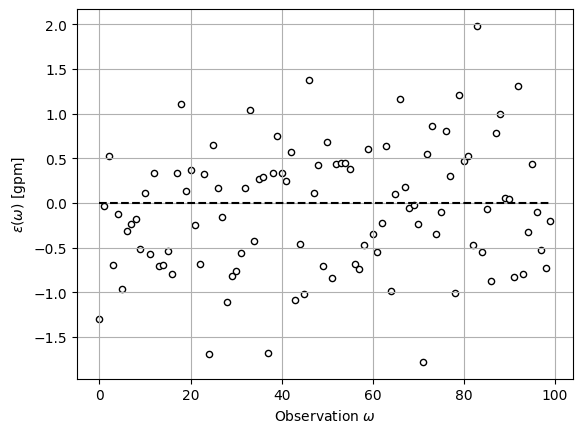

In [4]:
plt.scatter(omega, epsilon, marker='o', s=20, color='white', edgecolor='black')
plt.plot(omega, np.zeros(S), 'k--')
plt.xlabel(r'Observation $\omega$')
plt.ylabel(r'$\epsilon(\omega)$ [gpm]')
plt.grid(True)
plt.show()